# Coding Assignment 2
What can a traveller learn from a year of flights?

## 1. Build the analysis sample
### 1(a) Dataset structure and duplicate records

In [1]:
import pandas as pd

In [2]:
flights = pd.read_csv("data/flights.csv.zip")
airlines = pd.read_csv("data/airlines.csv")

In [3]:
print(flights.shape)
print(airlines.shape)

(336776, 19)
(16, 2)


In [4]:
print(flights["arr_delay"].dtype)

float64


In [5]:
print(flights.duplicated().sum())

0


Each row in the flights dataset represents one scheduled flight, while each row in the airlines dataset represents one airline and its carrier code. The datasets contain 336,776 flight records (19 columns) and 16 airlines (2 columns), respectively. Arrival delay is stored as float64. No exact duplicate flight records were found across the original columns, so no rows need to be removed.

### 1(b) Missing delays and late-arrival indicator

In [6]:
print(flights["arr_delay"].notna().sum())
print(flights["arr_delay"].isna().sum())

327346
9430


In [7]:
print(327346 + 9430 == len(flights))

True


In [8]:
flights["late_arrival"] = (flights["arr_delay"] >= 15).astype("boolean")
flights.loc[flights["arr_delay"].isna(), "late_arrival"] = pd.NA

In [9]:
print(flights["late_arrival"].isna().sum())

9430


In [10]:
test_delays = pd.Series([-5, 14, 15, pd.NA], dtype="Float64")

test_late = (test_delays >= 15).astype("boolean")

print(pd.DataFrame({
    "Arrival delay": test_delays,
    "Late arrival": test_late
}))

   Arrival delay  Late arrival
0           -5.0         False
1           14.0         False
2           15.0          True
3           <NA>          <NA>


A flight is classified as late if it arrives at least 15 minutes after its scheduled arrival time. Early arrivals and delays below 15 minutes are classified as not late. Flights with missing arrival delays retain a missing outcome rather than being classified as on time.

## 2. Attach the airline names

In [11]:
print(airlines["carrier"].is_unique)
print(airlines["carrier"].duplicated().sum())

True
0


In [12]:
flights_named = flights.merge(
    airlines,
    on="carrier",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Before:", len(flights))
print("After:", len(flights_named))

Before: 336776
After: 336776


In [13]:
print(flights_named["_merge"].value_counts())

_merge
both          336776
left_only          0
right_only         0
Name: count, dtype: int64


In [14]:
flights_named[["carrier", "name", "arr_delay", "late_arrival"]].head(10)

,carrier,name,arr_delay,late_arrival
0,UA,United Air Lines Inc.,11.0,False
1,UA,United Air Lines Inc.,20.0,True
2,AA,American Airlines Inc.,33.0,True
3,B6,JetBlue Airways,-18.0,False
4,DL,Delta Air Lines Inc.,-25.0,False
5,UA,United Air Lines Inc.,12.0,False
6,B6,JetBlue Airways,19.0,True
7,EV,ExpressJet Airlines Inc.,-14.0,False
8,B6,JetBlue Airways,-8.0,False
9,AA,American Airlines Inc.,8.0,False


### Results of the airline lookup

Each of the 16 airline codes appears exactly once in the lookup dataset. The datasets were merged using `carrier` with a many-to-one validation and a left join.

The number of flight records remained unchanged at 336,776. All flight records matched an airline, with zero unmatched codes.

## 3. Give the editor a table they can check

### 3(a) Five busiest airlines and their late-arrival rates

We first identify the five busiest airlines based on their total number of scheduled flight records, including flights with missing arrival delays.

For each airline, we calculate the number of scheduled flights, flights with known arrival delays, late arrivals (15 minutes or more), and the percentage of late arrivals among flights with known delays.

In [15]:
airline_counts = flights_named["name"].value_counts()

print(airline_counts.head(5))

name
United Air Lines Inc.       58665
JetBlue Airways             54635
ExpressJet Airlines Inc.    54173
Delta Air Lines Inc.        48110
American Airlines Inc.      32729
Name: count, dtype: int64


In [16]:
top_five = airline_counts.head(5).index

print(top_five.tolist())

['United Air Lines Inc.', 'JetBlue Airways', 'ExpressJet Airlines Inc.', 'Delta Air Lines Inc.', 'American Airlines Inc.']


In [17]:
top_five_flights = flights_named[flights_named["name"].isin(top_five)]

print(top_five_flights.shape)

(248312, 22)


In [18]:
summary_top5 = top_five_flights.groupby("name").agg(
    scheduled_flights=("carrier", "size"),
    known_delays=("arr_delay", "count"),
    late_arrivals=("late_arrival", "sum")
)

summary_top5

,scheduled_flights,known_delays,late_arrivals
name,,,
American Airlines Inc.,32729,31947,6203
Delta Air Lines Inc.,48110,47658,9038
ExpressJet Airlines Inc.,54173,51108,16399
JetBlue Airways,54635,54049,14567
United Air Lines Inc.,58665,57782,13004


In [19]:
summary_top5["percent_late"] = (
    summary_top5["late_arrivals"] / summary_top5["known_delays"] * 100
)

summary_top5

,scheduled_flights,known_delays,late_arrivals,percent_late
name,,,,
American Airlines Inc.,32729,31947,6203,19.416534
Delta Air Lines Inc.,48110,47658,9038,18.964287
ExpressJet Airlines Inc.,54173,51108,16399,32.086953
JetBlue Airways,54635,54049,14567,26.95147
United Air Lines Inc.,58665,57782,13004,22.505278


In [20]:
summary_top5 = summary_top5.sort_values(
    "scheduled_flights", ascending=False
)

summary_top5

,scheduled_flights,known_delays,late_arrivals,percent_late
name,,,,
United Air Lines Inc.,58665,57782,13004,22.505278
JetBlue Airways,54635,54049,14567,26.95147
ExpressJet Airlines Inc.,54173,51108,16399,32.086953
Delta Air Lines Inc.,48110,47658,9038,18.964287
American Airlines Inc.,32729,31947,6203,19.416534


In [21]:
all_airlines = pd.DataFrame({
    "scheduled_flights": [len(flights_named)],
    "known_delays": [flights_named["arr_delay"].count()],
    "late_arrivals": [flights_named["late_arrival"].sum()]
}, index=["All airlines"])

all_airlines

,scheduled_flights,known_delays,late_arrivals
All airlines,336776,327346,80100


In [22]:
all_airlines["percent_late"] = (
    all_airlines["late_arrivals"] / all_airlines["known_delays"] * 100
)

summary_table = pd.concat([summary_top5, all_airlines])

summary_table

,scheduled_flights,known_delays,late_arrivals,percent_late
United Air Lines Inc.,58665,57782,13004,22.505278
JetBlue Airways,54635,54049,14567,26.95147
ExpressJet Airlines Inc.,54173,51108,16399,32.086953
Delta Air Lines Inc.,48110,47658,9038,18.964287
American Airlines Inc.,32729,31947,6203,19.416534
All airlines,336776,327346,80100,24.469522


In [23]:
final_table = summary_table.rename(columns={
    "scheduled_flights": "Scheduled flights",
    "known_delays": "Known arrival delays",
    "late_arrivals": "Late arrivals",
    "percent_late": "Percentage late"
})

final_table["Percentage late"] = final_table["Percentage late"].map(
    lambda x: f"{x:.1f}%"
)

final_table = final_table.rename_axis("Airline")

final_table

,Scheduled flights,Known arrival delays,Late arrivals,Percentage late
Airline,,,,
United Air Lines Inc.,58665,57782,13004,22.5%
JetBlue Airways,54635,54049,14567,27.0%
ExpressJet Airlines Inc.,54173,51108,16399,32.1%
Delta Air Lines Inc.,48110,47658,9038,19.0%
American Airlines Inc.,32729,31947,6203,19.4%
All airlines,336776,327346,80100,24.5%


### 3(b) Independent verification of United Airlines

To verify the summary table, we independently calculate United Airlines' late-arrival rate using its original flight records rather than the aggregated table.

In [24]:
united = flights_named[
    flights_named["carrier"] == "UA"
]

print(len(united))

58665


In [25]:
united_known = united["arr_delay"].count()
united_late = united["late_arrival"].sum()

united_rate = united_late / united_known * 100

print("Known arrival delays:", united_known)
print("Late arrivals:", united_late)
print(f"Calculation: {united_late} / {united_known} × 100 = {united_rate:.1f}%")

print("Matches summary:", round(united_rate, 1) ==
      round(summary_table.loc["United Air Lines Inc.", "percent_late"], 1))

Known arrival delays: 57782
Late arrivals: 13004
Calculation: 13004 / 57782 × 100 = 22.5%
Matches summary: True


United Airlines had 13,004 late arrivals among 57,782 flights with known arrival delays. Its late-arrival rate was 22.5%, independently confirming the result in the summary table.

### 3(c) Alternative denominator for the overall late-arrival rate

In [26]:
overall_late = flights_named["late_arrival"].sum()
overall_known = flights_named["arr_delay"].count()
overall_scheduled = len(flights_named)

original_rate = overall_late / overall_known * 100
alternative_rate = overall_late / overall_scheduled * 100

print(f"Original rate: {original_rate:.2f}%")
print(f"Alternative rate: {alternative_rate:.2f}%")

Original rate: 24.47%
Alternative rate: 23.78%


In [27]:
difference_pp = alternative_rate - original_rate

print(f"Difference: {difference_pp:.2f} percentage points")

Difference: -0.69 percentage points


Using only flights with known arrival delays, the overall late-arrival rate is 24.47% (80,100 / 327,346).

Using all scheduled flights instead gives 23.78% (80,100 / 336,776), a decrease of 0.69 percentage points.

The alternative denominator includes 9,430 flights with missing arrival delays. These flights cannot be classified as late or on time, but including them in the denominator lowers the reported late-arrival rate.

## 4. Pitch and illustrate our own finding

### 4(a) Research question and target audience

**Reader:** A traveller concerned about flight delays.

**Research question:** Are longer flights more likely to recover from late departures?

We examine flights departing from New York-area airports in 2013 that left at least 15 minutes late.

A flight is considered to have recovered sufficiently if its arrival delay was less than 15 minutes.

We compare recovery rates across four distance categories:
- Under 500 miles
- 500–999 miles
- 1,000–1,499 miles
- 1,500 miles or more

Flights with missing arrival delays are excluded. The recovery rate is the percentage of eligible flights arriving less than 15 minutes late.

The analysis includes 72,420 flights with known arrival delays and distances. Of these, 14,543 arrived less than 15 minutes late despite departing at least 15 minutes late

In [28]:
late_departures = flights_named[
    (flights_named["dep_delay"] >= 15) &
    (flights_named["arr_delay"].notna()) &
    (flights_named["distance"].notna())
].copy()

In [29]:
late_departures["recovered"] = late_departures["arr_delay"] < 15

print("Flights in analysis:", len(late_departures))
print("Recovered sufficiently:", late_departures["recovered"].sum())

Flights in analysis: 72420
Recovered sufficiently: 14543


In [30]:
late_departures["distance_group"] = pd.cut(
    late_departures["distance"],
    bins=[0, 500, 1000, 1500, float("inf")],
    labels=["Under 500", "500–999", "1,000–1,499", "1,500+"],
    right=False
)

late_departures[["distance", "distance_group"]].head(10)

,distance,distance_group
41,212,Under 500
85,937,500–999
96,719,500–999
119,544,500–999
135,1089,"1,000–1,499"
151,184,Under 500
171,764,500–999
174,1605,"1,500+"
178,1623,"1,500+"
187,228,Under 500


In [31]:
distance_summary = late_departures.groupby(
    "distance_group", observed=True
).agg(
    flights=("recovered", "size"),
    recovered=("recovered", "sum")
).reset_index()

distance_summary

,distance_group,flights,recovered
0,Under 500,18243,2699
1,500–999,24261,4266
2,"1,000–1,499",15218,3261
3,"1,500+",14698,4317


In [32]:
distance_summary["recovery_rate"] = (
    distance_summary["recovered"] / distance_summary["flights"] * 100
)

distance_summary.round(1)

,distance_group,flights,recovered,recovery_rate
0,Under 500,18243,2699,14.8
1,500–999,24261,4266,17.6
2,"1,000–1,499",15218,3261,21.4
3,"1,500+",14698,4317,29.4


### 4(b) Figure: Recovery rates by flight distance

We use a bar chart to compare the percentage of delayed departures that recovered sufficiently before arrival across four flight-distance categories.

In [33]:
import sys
print(sys.executable)

/Users/jonasmeksraitis/miniforge3/envs/research-methods/bin/python


In [35]:
import plotnine as pn

Matplotlib is building the font cache; this may take a moment.


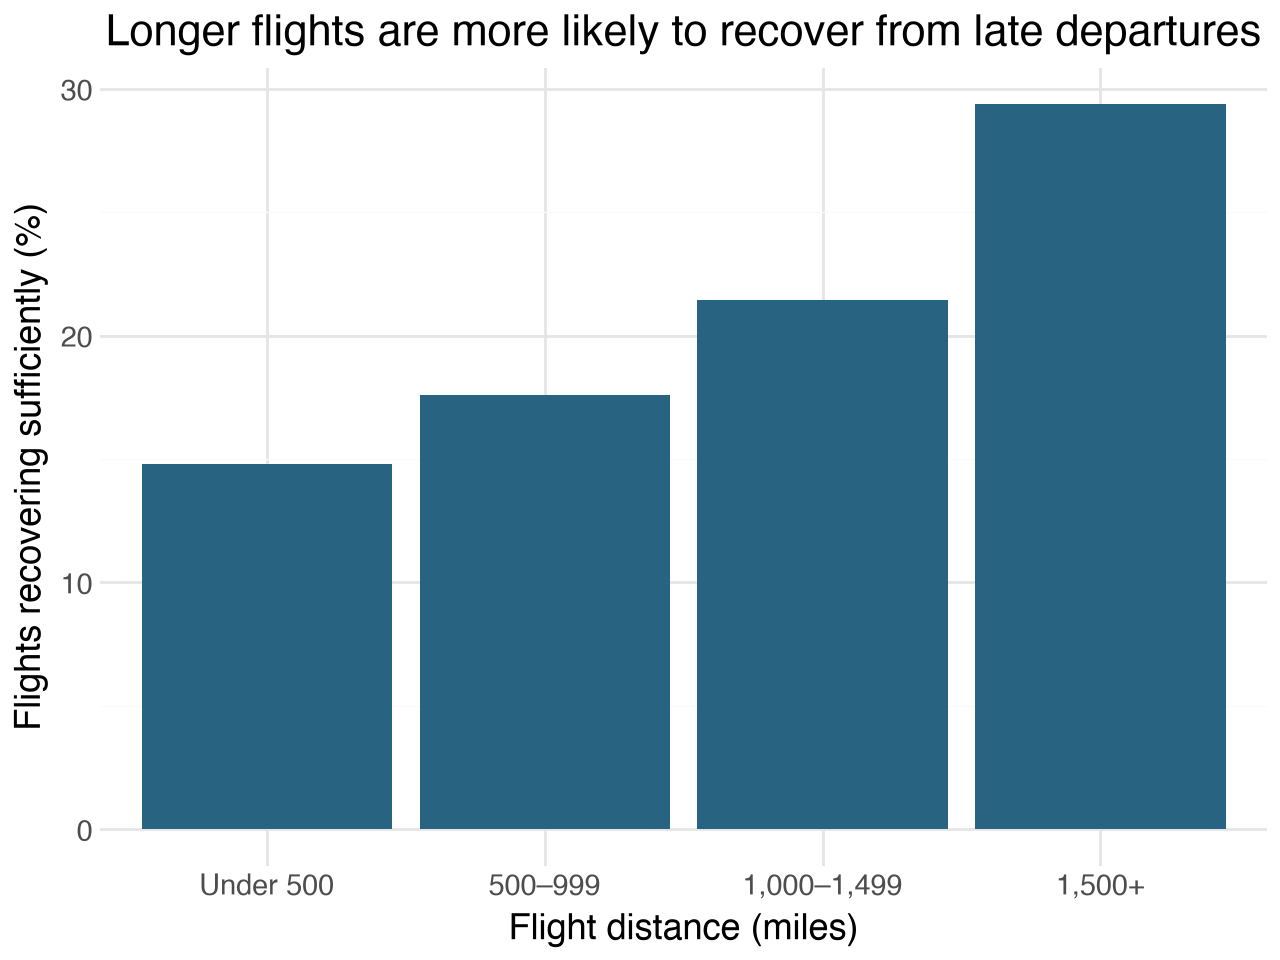

In [36]:
first_plot = (
    pn.ggplot(
        distance_summary,
        pn.aes("distance_group", "recovery_rate")
    )
    + pn.geom_col(fill="#286482")
    + pn.labs(
        title="Longer flights are more likely to recover from late departures",
        x="Flight distance (miles)",
        y="Flights recovering sufficiently (%)"
    )
    + pn.theme_minimal(base_size=13)
)

first_plot

### 4(c) Improving the figure design

The original figure uses vertical bars. We revise the presentation to make the comparison between distance groups easier to read.

In [37]:
distance_summary["rate_label"] = distance_summary["recovery_rate"].map(
    lambda x: f"{x:.1f}%"
)

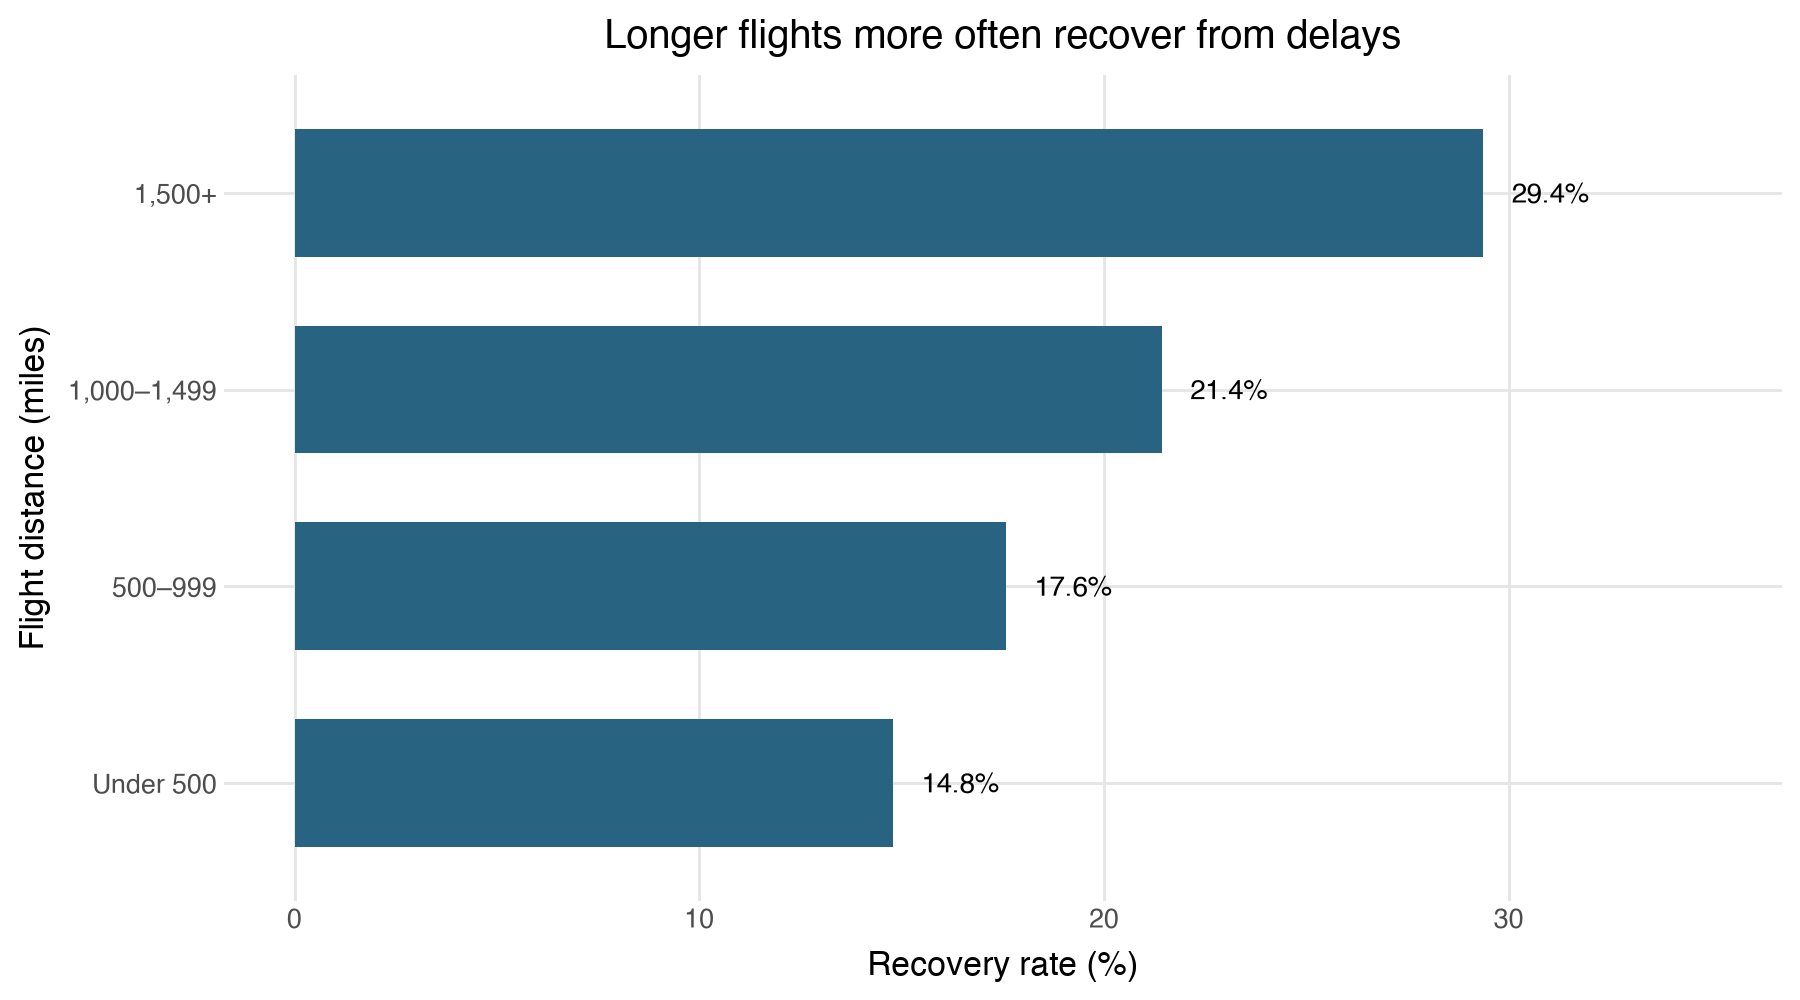

In [38]:
final_plot = (
    pn.ggplot(
        distance_summary,
        pn.aes("distance_group", "recovery_rate")
    )
    + pn.geom_col(fill="#286482", width=0.65)
    + pn.geom_text(
        pn.aes(label="rate_label"),
        ha="left",
        nudge_y=0.7,
        size=10
    )
    + pn.expand_limits(y=35)
    + pn.coord_flip()
    + pn.labs(
        title="Longer flights more often recover from delays",
        x="Flight distance (miles)",
        y="Recovery rate (%)"
    )
    + pn.theme_minimal(base_size=12)
    + pn.theme(
        figure_size=(9, 5),
        panel_grid_minor=pn.element_blank()
    )
)

final_plot

The revised figure uses horizontal bars and direct percentage labels, making the differences between distance categories easier to compare without estimating values from the axis. No numerical information is lost, although the original vertical presentation is replaced.

### 4(d) Figure caption

Among 72,420 flights departing JFK, LaGuardia, or Newark at least 15 minutes late in 2013, longer flights were more likely to arrive less than 15 minutes late. The recovery rate increased from 14.8% for flights under 500 miles to 29.4% for flights of at least 1,500 miles, a difference of 14.6 percentage points. The analysis uses flights with known arrival delays and distances. Source: U.S. Bureau of Transportation Statistics, via nycflights13. This descriptive comparison cannot establish that longer distances cause better recovery, because airlines, routes, and scheduling practices may also differ.

In [40]:
final_plot.save("figure.png", width=9, height=5, dpi=300)

/Users/jonasmeksraitis/miniforge3/envs/research-methods/lib/python3.12/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 9 x 5 in image.
/Users/jonasmeksraitis/miniforge3/envs/research-methods/lib/python3.12/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figure.png
